In [ ]:
#!pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp313-cp313-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Usi


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
train = pd.read_csv('../data/train.csv')

In [6]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [9]:
pd.crosstab(train['Sex'], train['Survived'], margins = True)

Survived,0,1,All
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


In [10]:
pd.crosstab(train['Pclass'], train['Survived'], margins = True)

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


Процент выживших по классам:
 Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


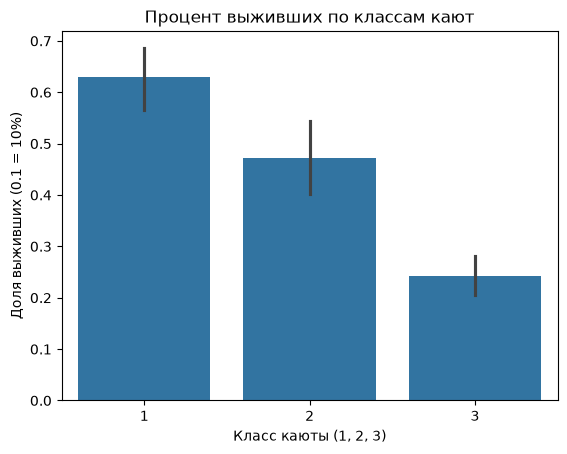

In [73]:
pclass_survival = train.groupby('Pclass')['Survived'].mean() * 100
print('Процент выживших по классам:\n', pclass_survival)
sns.barplot(x='Pclass', y='Survived', data=train)
plt.title('Процент выживших по классам кают')
plt.xlabel('Класс каюты (1, 2, 3)')
plt.ylabel('Доля выживших (0.1 = 10%)')
plt.show()

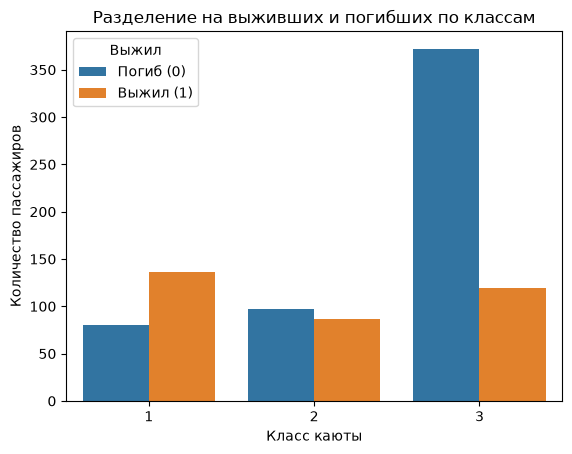

In [15]:
sns.countplot(x='Pclass', hue='Survived', data=train)
plt.title('Разделение на выживших и погибших по классам')
plt.xlabel('Класс каюты')
plt.ylabel('Количество пассажиров')
plt.legend(title='Выжил', labels=['Погиб (0)', 'Выжил (1)'])
plt.show()


In [16]:
pd.crosstab([train.Sex, train.Survived], train.Pclass, margins = True)

Pclass             1    2    3  All
Sex    Survived                    
female 0           3    6   72   81
       1          91   70   72  233
male   0          77   91  300  468
       1          45   17   47  109
All              216  184  491  891

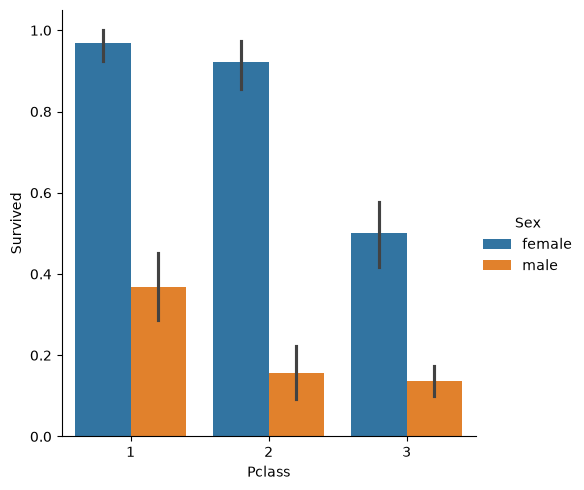

In [20]:
sns.catplot(x = 'Pclass', y = 'Survived', hue='Sex', kind = 'bar', data=train)
plt.show()

In [ ]:
#Преобразовываем возраст в 5 промежутков
bins = [0, 12, 20, 40, 60, 90]
labels = ['Дети (0-12)', 'Молодёж (12-20)', 'Взрослые (20-40)', 'Зрелые (40-60)', 'Пожилые (60-90)']
train['AgeGroup'] = pd.cut(train['Age'], bins = bins, labels = labels)
pd.crosstab(train['AgeGroup'], train['Survived'], margins = True)

Survived,0,1,All
AgeGroup,,,
Дети (0-12),29,40,69
Молодёж (12-20),68,42,110
Взрослые (20-40),232,153,385
Зрелые (40-60),78,50,128
Пожилые (60-90),17,5,22
All,424,290,714


In [26]:
train.groupby('AgeGroup', observed = False)['Survived'].mean() * 100

AgeGroup
Дети (0-12)         57.971014
Молодёж (12-20)     38.181818
Взрослые (20-40)    39.740260
Зрелые (40-60)      39.062500
Пожилые (60-90)     22.727273
Name: Survived, dtype: float64

In [28]:
pd.crosstab([train['Pclass'], train['AgeGroup']], train['Survived'], margins = True)

Survived                   0    1  All
Pclass AgeGroup                       
1      Дети (0-12)         1    3    4
       Молодёж (12-20)     3   14   17
       Взрослые (20-40)   23   66   89
       Зрелые (40-60)     26   36   62
       Пожилые (60-90)    11    3   14
2      Дети (0-12)         0   17   17
       Молодёж (12-20)     9    9   18
       Взрослые (20-40)   60   44  104
       Зрелые (40-60)     19   12   31
       Пожилые (60-90)     2    1    3
3      Дети (0-12)        28   20   48
       Молодёж (12-20)    56   19   75
       Взрослые (20-40)  149   43  192
       Зрелые (40-60)     33    2   35
       Пожилые (60-90)     4    1    5
All                      424  290  714

In [29]:
pd.crosstab([train['Pclass'], train['Sex'], train['AgeGroup']], train['Survived'], margins = True)

Survived                          0    1  All
Pclass Sex    AgeGroup                       
1      female Дети (0-12)         1    0    1
              Молодёж (12-20)     0   13   13
              Взрослые (20-40)    1   44   45
              Зрелые (40-60)      1   23   24
              Пожилые (60-90)     0    2    2
       male   Дети (0-12)         0    3    3
              Молодёж (12-20)     3    1    4
              Взрослые (20-40)   22   22   44
              Зрелые (40-60)     25   13   38
              Пожилые (60-90)    11    1   12
2      female Дети (0-12)         0    8    8
              Молодёж (12-20)     0    8    8
              Взрослые (20-40)    4   41   45
              Зрелые (40-60)      2   11   13
       male   Дети (0-12)         0    9    9
              Молодёж (12-20)     9    1   10
              Взрослые (20-40)   56    3   59
              Зрелые (40-60)     17    1   18
              Пожилые (60-90)     2    1    3
3      female Дети (0-12)        12   11   23
              Молодёж (12-20)    11   13   24
              Взрослые (20-40)   24   22   46
              Зрелые (40-60)      8    0    8
              Пожилые (60-90)     0    1    1
       male   Дети (0-12)        16    9   25
              Молодёж (12-20)    45    6   51
              Взрослые (20-40)  125   21  146
              Зрелые (40-60)     25    2   27
              Пожилые (60-90)     4    0    4
All                             424  290  714

In [30]:
test = pd.read_csv('../data/test.csv')

In [ ]:
#Преобразовываем ранги людей к 5 рангам, которые зависят от возраста и пола
titles = {
    'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs',
    'Dr': 'Other', 'Rev': 'Other', 'Col': 'Other', 
    'Major': 'Other', 'Capt': 'Other', 'Countess': 'Other',
    'Lady': 'Other', 'Jonkheer': 'Other', 'Don': 'Other', 
    'Sir': 'Other', 'Dona': 'Other'
}

train['Title'] = train['Name'].str.extract(r' ([A-Za-z]+)\.', expand = False)
train['Title'] = train['Title'].replace(titles)

test['Title'] = test['Name'].str.extract(r' ([A-Za-z]+)\.', expand = False)
test['Title'] = test['Title'].replace(titles)
train['Title'].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64

In [35]:
pd.crosstab(train['Title'], train['Survived'], margins = True)

Survived,0,1,All
Title,,,
Master,17,23,40
Miss,55,130,185
Mr,436,81,517
Mrs,26,100,126
Other,15,8,23
All,549,342,891


In [36]:
pd.crosstab(train['Title'], train['Survived'], normalize = 'index') * 100

Survived,0,1
Title,,
Master,42.500000,57.500000
Miss,29.729730,70.270270
Mr,84.332689,15.667311
Mrs,20.634921,79.365079
Other,65.217391,34.782609


In [38]:
pd.crosstab(train['Embarked'], train['Survived'], margins = True)

Survived,0,1,All
Embarked,,,
C,75,93,168
Q,47,30,77
S,427,217,644
All,549,340,889


In [39]:
pd.crosstab(train['Embarked'], train['Survived'], normalize = 'index') * 100

Survived,0,1
Embarked,,
C,44.642857,55.357143
Q,61.038961,38.961039
S,66.304348,33.695652


In [40]:
pd.crosstab([train['Embarked'], train['Pclass']], train['Survived'], margins = True)

Survived           0    1  All
Embarked Pclass               
C        1        26   59   85
         2         8    9   17
         3        41   25   66
Q        1         1    1    2
         2         1    2    3
         3        45   27   72
S        1        53   74  127
         2        88   76  164
         3       286   67  353
All              549  340  889

In [37]:
pd.crosstab([train['Embarked'],train['Pclass'], train['Sex']], train['Survived'], margins = True)

Survived                  0    1  All
Embarked Pclass Sex                  
C        1      female    1   42   43
                male     25   17   42
         2      female    0    7    7
                male      8    2   10
         3      female    8   15   23
                male     33   10   43
Q        1      female    0    1    1
                male      1    0    1
         2      female    0    2    2
                male      1    0    1
         3      female    9   24   33
                male     36    3   39
S        1      female    2   46   48
                male     51   28   79
         2      female    6   61   67
                male     82   15   97
         3      female   55   33   88
                male    231   34  265
All                     549  340  889

In [41]:
pd.crosstab([train['Embarked'],train['Pclass'], train['Sex']], train['Survived'], normalize = 'index') * 100

Survived                         0           1
Embarked Pclass Sex                           
C        1      female    2.325581   97.674419
                male     59.523810   40.476190
         2      female    0.000000  100.000000
                male     80.000000   20.000000
         3      female   34.782609   65.217391
                male     76.744186   23.255814
Q        1      female    0.000000  100.000000
                male    100.000000    0.000000
         2      female    0.000000  100.000000
                male    100.000000    0.000000
         3      female   27.272727   72.727273
                male     92.307692    7.692308
S        1      female    4.166667   95.833333
                male     64.556962   35.443038
         2      female    8.955224   91.044776
                male     84.536082   15.463918
         3      female   62.500000   37.500000
                male     87.169811   12.830189

In [ ]:
#Заполняем пропуски в Embarked 
train['Embarked'] = train['Embarked'].fillna('S')
test['Embarked'] = test['Embarked'].fillna('S')

print('train:', train['Embarked'].isnull().any())
print('test:', test['Embarked'].isnull().any())

train: False
test: False


In [44]:
pd.crosstab(train['SibSp'], train['Survived'], margins = True)

Survived,0,1,All
SibSp,,,
0,398,210,608
1,97,112,209
2,15,13,28
3,12,4,16
4,15,3,18
5,5,0,5
8,7,0,7
All,549,342,891


In [45]:
pd.crosstab(train['SibSp'], train['Survived'], normalize = 'index') * 100

Survived,0,1
SibSp,,
0,65.460526,34.539474
1,46.411483,53.588517
2,53.571429,46.428571
3,75.000000,25.000000
4,83.333333,16.666667
5,100.000000,0.000000
8,100.000000,0.000000


In [46]:
pd.crosstab([train['SibSp'], train['Pclass']], train['Survived'], margins = True)

Survived        0    1  All
SibSp Pclass               
0     1        60   77  137
      2        70   50  120
      3       268   83  351
1     1        18   53   71
      2        23   32   55
      3        56   27   83
2     1         1    4    5
      2         4    4    8
      3        10    5   15
3     1         1    2    3
      2         0    1    1
      3        11    1   12
4     3        15    3   18
5     3         5    0    5
8     3         7    0    7
All           549  342  891

In [47]:
pd.crosstab([train['SibSp'], train['Pclass']], train['Survived'], normalize = 'index') * 100

Survived               0           1
SibSp Pclass                        
0     1        43.795620   56.204380
      2        58.333333   41.666667
      3        76.353276   23.646724
1     1        25.352113   74.647887
      2        41.818182   58.181818
      3        67.469880   32.530120
2     1        20.000000   80.000000
      2        50.000000   50.000000
      3        66.666667   33.333333
3     1        33.333333   66.666667
      2         0.000000  100.000000
      3        91.666667    8.333333
4     3        83.333333   16.666667
5     3       100.000000    0.000000
8     3       100.000000    0.000000

In [48]:
pd.crosstab([train['SibSp'], train['Pclass'], train['Sex']], train['Survived'], margins = True)

Survived               0    1  All
SibSp Pclass Sex                  
0     1      female    1   48   49
             male     59   29   88
      2      female    3   41   44
             male     67    9   76
      3      female   33   48   81
             male    235   35  270
1     1      female    2   38   40
             male     16   15   31
      2      female    3   25   28
             male     20    7   27
      3      female   21   17   38
             male     35   10   45
2     1      female    0    3    3
             male      1    1    2
      2      female    0    3    3
             male      4    1    5
      3      female    3    4    7
             male      7    1    8
3     1      female    0    2    2
             male      1    0    1
      2      female    0    1    1
      3      female    7    1    8
             male      4    0    4
4     3      female    4    2    6
             male     11    1   12
5     3      female    1    0    1
             male      4    0    4
8     3      female    3    0    3
             male      4    0    4
All                  549  342  891

In [49]:
pd.crosstab([train['SibSp'], train['Pclass'], train['Sex']], train['Survived'], normalize = 'index') * 100

Survived                      0           1
SibSp Pclass Sex                           
0     1      female    2.040816   97.959184
             male     67.045455   32.954545
      2      female    6.818182   93.181818
             male     88.157895   11.842105
      3      female   40.740741   59.259259
             male     87.037037   12.962963
1     1      female    5.000000   95.000000
             male     51.612903   48.387097
      2      female   10.714286   89.285714
             male     74.074074   25.925926
      3      female   55.263158   44.736842
             male     77.777778   22.222222
2     1      female    0.000000  100.000000
             male     50.000000   50.000000
      2      female    0.000000  100.000000
             male     80.000000   20.000000
      3      female   42.857143   57.142857
             male     87.500000   12.500000
3     1      female    0.000000  100.000000
             male    100.000000    0.000000
      2      female    0.000000  100.000000
      3      female   87.500000   12.500000
             male    100.000000    0.000000
4     3      female   66.666667   33.333333
             male     91.666667    8.333333
5     3      female  100.000000    0.000000
             male    100.000000    0.000000
8     3      female  100.000000    0.000000
             male    100.000000    0.000000

In [50]:
pd.crosstab(train['Parch'], train['Survived'], margins = True)

Survived,0,1,All
Parch,,,
0,445,233,678
1,53,65,118
2,40,40,80
3,2,3,5
4,4,0,4
5,4,1,5
6,1,0,1
All,549,342,891


In [51]:
pd.crosstab(train['Parch'], train['Survived'], normalize = 'index') * 100

Survived,0,1
Parch,,
0,65.634218,34.365782
1,44.915254,55.084746
2,50.000000,50.000000
3,40.000000,60.000000
4,100.000000,0.000000
5,80.000000,20.000000
6,100.000000,0.000000


In [52]:
pd.crosstab([train['Parch'], train['Pclass']], train['Survived'], margins = True)

Survived        0    1  All
Parch Pclass               
0     1        64   99  163
      2        86   48  134
      3       295   86  381
1     1        10   21   31
      2         8   24   32
      3        35   20   55
2     1         5   16   21
      2         3   13   16
      3        32   11   43
3     2         0    2    2
      3         2    1    3
4     1         1    0    1
      3         3    0    3
5     3         4    1    5
6     3         1    0    1
All           549  342  891

In [ ]:
#Преобразовываем стоимость в 4 промежутка
train['FareBand'] = pd.qcut(train['Fare'], 4, labels = [0, 1, 2, 3])
test['FareBand'] = pd.qcut(test['Fare'], 4, labels = [0, 1, 2, 3])
pd.crosstab(train['FareBand'], train['Survived'], margins = True)

Survived,0,1,All
FareBand,,,
0,179,44,223
1,156,68,224
2,121,101,222
3,93,129,222
All,549,342,891


In [54]:
pd.crosstab(train['FareBand'], train['Survived'], normalize = 'index') * 100

Survived,0,1
FareBand,,
0,80.269058,19.730942
1,69.642857,30.357143
2,54.504505,45.495495
3,41.891892,58.108108


In [55]:
pd.crosstab([train['FareBand'], train['Pclass']], train['Survived'], margins = True)

Survived           0    1  All
FareBand Pclass               
0        1         6    0    6
         2         6    0    6
         3       167   44  211
1        2        53   33   86
         3       103   35  138
2        1        24   27   51
         2        28   42   70
         3        69   32  101
3        1        50  109  159
         2        10   12   22
         3        33    8   41
All              549  342  891

In [71]:
#Преобразовываем все категориальные и строковые признаки в числовые, считаем корреляцию
test['Fare'] = test['Fare'].fillna(test['Fare'].median())
title_mapping = {'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Master': 3, 'Other': 4}
for dt in [train, test]:
    dt['Title'] = dt['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    dt['Title'] = dt['Title'].replace({'Mlle':'Miss', 'Ms':'Miss', 'Mme':'Mrs', 'Dr':'Other', 'Rev':'Other', 'Col':'Other', 'Major':'Other', 'Capt':'Other', 'Countess':'Other', 'Lady':'Other', 'Jonkheer':'Other', 'Don':'Other', 'Sir':'Other', 'Dona':'Other'})
    dt['Title'] = dt['Title'].map(title_mapping).fillna(4).astype(int)
    dt['Sex'] = dt['Sex'].replace({'female': 0, 'male': 1})
    dt['Embarked'] = dt['Embarked'].replace({'S': 0, 'C': 1, 'Q': 2})
    dt['Fare_cat'] = pd.qcut(dt['Fare'].fillna(dt['Fare'].median()), 4, labels=[0, 1, 2, 3]).astype(int)
    dt['Age'] = dt['Age'].fillna(dt['Age'].median())
    dt['AgeGroup'] = pd.cut(dt['Age'], bins = [0, 12, 20, 40, 60, 100], labels = [0, 1, 2, 3, 4]).astype(int)
    #Для удобства создаём 2 новых признака, которые чётко разделяют кол-во всех родственников
    dt['Family_Size'] = dt['SibSp'] + dt['Parch'] + 1
    dt['Alone'] = (dt['Family_Size'] == 1).astype(int)
    
train[['Survived', 'Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked', 'Title', 'AgeGroup', 'Family_Size', 'Alone', 'Fare_cat']].info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Survived     891 non-null    int64
 1   Pclass       891 non-null    int64
 2   Sex          891 non-null    int64
 3   SibSp        891 non-null    int64
 4   Parch        891 non-null    int64
 5   Embarked     891 non-null    int64
 6   Title        891 non-null    int64
 7   AgeGroup     891 non-null    int64
 8   Family_Size  891 non-null    int64
 9   Alone        891 non-null    int64
 10  Fare_cat     891 non-null    int64
dtypes: int64(11)
memory usage: 76.7 KB


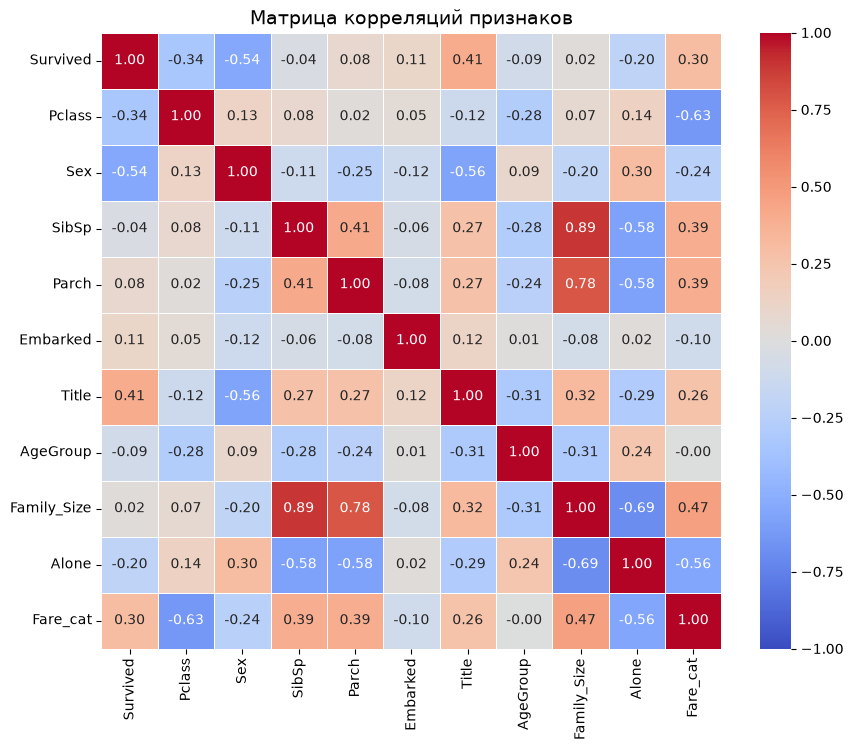

In [72]:
#Выводим корреляцию
features = ['Survived', 'Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked', 'Title', 'AgeGroup', 'Family_Size', 'Alone', 'Fare_cat']
plt.figure(figsize = (10, 8))
sns.heatmap(train[features].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', vmin = -1, vmax = 1, linewidths = 0.5)
plt.title('Матрица корреляций признаков', fontsize = 14)
plt.show()

In [75]:
#One-hot encoding
dt = pd.concat([train, test], ignore_index = True)
dt = pd.get_dummies(dt, columns = ['Embarked', 'Title'], drop_first = True, dtype = int)
display(dt.head())
train_clean = dt[dt['Survived'].notnull()].copy()
test_clean = dt[dt['Survived'].isnull()].drop(columns = ['Survived']).copy()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,IsAlone,Fare_cat,Family_Size,Alone,Embarked_1,Embarked_2,Title_1,Title_2,Title_3,Title_4
0,1,0.0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,...,0,0,2,0,0,0,0,0,0,0
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,...,0,3,2,0,1,0,1,0,0,0
2,3,1.0,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,...,1,1,1,1,0,0,0,1,0,0
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,...,0,3,2,0,0,0,1,0,0,0
4,5,0.0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,...,1,1,1,1,0,0,0,0,0,0


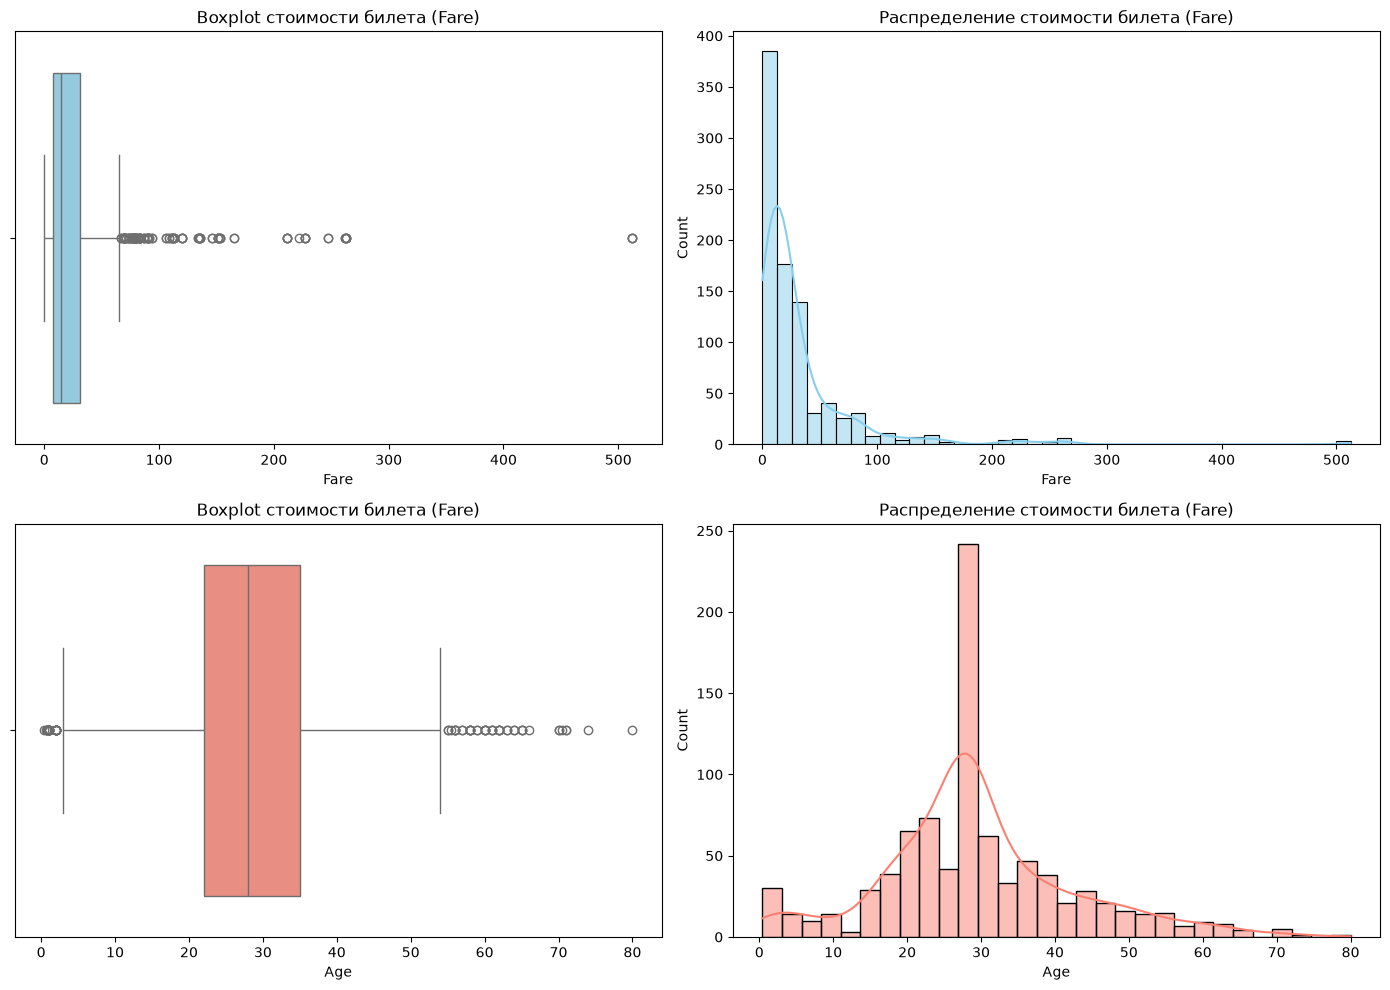

In [76]:
fig, axes = plt.subplots(2, 2, figsize = (14, 10))

sns.boxplot(x = train['Fare'], ax = axes[0, 0], color = 'skyblue')
axes[0, 0].set_title('Boxplot стоимости билета (Fare)')

sns.histplot(train['Fare'], kde = True, ax = axes[0, 1], bins = 40, color = 'skyblue')
axes[0, 1].set_title('Распределение стоимости билета (Fare)')

sns.boxplot(x = train['Age'], ax = axes[1, 0], color = 'salmon')
axes[1, 0].set_title('Boxplot стоимости билета (Fare)')

sns.histplot(train['Age'].dropna(), kde = True, ax = axes[1, 1], bins = 30, color = 'salmon')
axes[1, 1].set_title('Распределение стоимости билета (Fare)')

plt.tight_layout()
plt.show()

In [77]:
print('Самые дорогие билеты:')
display(train.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']])

print('\nБесплатные билеты (Fare = 0):')
display(train[train['Fare'] == 0][['Name', 'Pclass', 'Fare', 'Survived']])

Самые дорогие билеты:


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,1
438,"Fortune, Mr. Mark",1,263.0000,0
311,"Ryerson, Miss. Emily Borie",1,262.3750,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,1
118,"Baxter, Mr. Quigg Edmond",1,247.5208,0



Бесплатные билеты (Fare = 0):


,Name,Pclass,Fare,Survived
179,"Leonard, Mr. Lionel",3,0.0,0
263,"Harrison, Mr. William",1,0.0,0
271,"Tornquist, Mr. William Henry",3,0.0,1
277,"Parkes, Mr. Francis ""Frank""",2,0.0,0
302,"Johnson, Mr. William Cahoone Jr",3,0.0,0
413,"Cunningham, Mr. Alfred Fleming",2,0.0,0
466,"Campbell, Mr. William",2,0.0,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,0.0,0
597,"Johnson, Mr. Alfred",3,0.0,0
633,"Parr, Mr. William Henry Marsh",1,0.0,0


In [79]:
from preprocessing import train_clean, test_clean
train_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Family_Size,Alone,Fare_log,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Other
0,0.0,3,1,22.0,1,0,7.2500,2,0,2.110213,0,1,0,1,0,0
1,1.0,1,0,38.0,1,0,71.2833,2,0,4.280593,0,0,0,0,1,0
2,1.0,3,0,26.0,0,0,7.9250,1,1,2.188856,0,1,1,0,0,0
3,1.0,1,0,35.0,1,0,53.1000,2,0,3.990834,0,1,0,0,1,0
4,0.0,3,1,35.0,0,0,8.0500,1,1,2.202765,0,1,0,1,0,0
